This file focuses on capturing as many special events as possible (ideally every event) in a long rugby video, approximately 45 minutes in duration, corresponding to one half of a rugby match.

# Approach 1: Using sound such as whistle combining with the change in scene like the density of players:

    Extract audio from the video

In [2]:
!ffmpeg -i Plan1_First_half.mp4 -vn -acodec pcm_s16le -ar 16000 -ac 1 -y temp_audio.wav

ffmpeg version 8.0.1 Copyright (c) 2000-2025 the FFmpeg developers
  built with clang version 19.1.7
  configuration: --prefix=/Users/tntran2/miniforge3/envs/mllm_rugby --cc=arm64-apple-darwin20.0.0-clang --cxx=arm64-apple-darwin20.0.0-clang++ --nm=arm64-apple-darwin20.0.0-nm --ar=arm64-apple-darwin20.0.0-ar --disable-doc --enable-openssl --enable-demuxer=dash --enable-hardcoded-tables --enable-libfreetype --enable-libharfbuzz --enable-libfontconfig --enable-libopenh264 --enable-libdav1d --enable-cross-compile --arch=arm64 --target-os=darwin --cross-prefix=arm64-apple-darwin20.0.0- --host-cc=/Users/runner/miniforge3/conda-bld/ffmpeg_1773007843831/_build_env/bin/x86_64-apple-darwin13.4.0-clang --enable-neon --disable-gnutls --enable-libvpx --enable-libass --enable-pthreads --enable-libopenvino --enable-gpl --enable-libx264 --enable-libx265 --enable-libmp3lame --enable-libaom --enable-libsvtav1 --enable-libxml2 --enable-pic --enable-shared --disable-static --enable-version3 --enable-zlib

In [3]:
import cv2
import librosa
import numpy as np
import subprocess
import os

video_path = "Plan1_First_half.mp4"
audio_path = "temp_audio.wav"

# ==========================================
# 1. SCENE CUT AT 1 FPS
# ==========================================
def extract_real_visual_signal(video_file):
    print("🎬 Extracting Visual Signal (1 FPS)...")
    cap = cv2.VideoCapture(video_file)
    
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    video_length_sec = int(total_frames / fps)
    
    visual_signal = np.zeros(video_length_sec)
    prev_frame = None
    
    for sec in range(video_length_sec):
        # Jump to the exact second
        cap.set(cv2.CAP_PROP_POS_MSEC, sec * 1000)
        ret, frame = cap.read()
        
        if not ret:
            break
            
        # Gray scale + Resize to reduce noise 
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.resize(gray, (160, 90)) 
        
        if prev_frame is not None:
            # Calculate pixel difference between 2 seconds
            diff = cv2.absdiff(gray, prev_frame)
            visual_signal[sec] = np.mean(diff)
            
        prev_frame = gray
        
        if sec % 300 == 0 and sec > 0:
            print(f"   Extracted {sec}/{video_length_sec} seconds...")

    cap.release()
    
    # Normalize to [0, 1]
    visual_signal = visual_signal / np.max(visual_signal)
    print("✅ Xong Visual Signal!")
    return visual_signal, video_length_sec

# ==========================================
# 2. EXTRACT AUDIO SIGNAL (AUDIO ENERGY)
# ==========================================
def extract_real_audio_signal(video_file, audio_temp_file, video_length_sec):
    print("🔊 Extracting Audio from Video using FFmpeg...")
    # Extract audio to a wav file (Mono, 16kHz for fast processing)
    cmd = f"ffmpeg -i {video_file} -q:a 0 -map a -ar 16000 -ac 1 -y {audio_temp_file}"
    subprocess.call(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
    
    print("🎵 Analyzing Audio Energy...")
    # Load audio bằng librosa
    y, sr = librosa.load(audio_temp_file, sr=16000)
    
    # Calculate Root Mean Square (RMS) Energy
    rms = librosa.feature.rms(y=y, frame_length=sr, hop_length=sr)[0]
    
    # Synchronize length with visual signal array (Trim/Pad with 0 if mismatch)
    audio_signal = np.zeros(video_length_sec)
    min_len = min(len(rms), video_length_sec)
    audio_signal[:min_len] = rms[:min_len]
    
    # Normalize to [0, 1]
    audio_signal = audio_signal / np.max(audio_signal)
    
    # Delete temp file for a clean server
    if os.path.exists(audio_temp_file):
        os.remove(audio_temp_file)
        
    print("✅ Xong Audio Signal!")
    return audio_signal

# ==========================================
# 3. RUN EXTRACTION
# ==========================================
real_visual_signal, video_duration = extract_real_visual_signal(video_path)
real_audio_signal = extract_real_audio_signal(video_path, audio_path, video_duration)

print("🚀 Ready to attach to UI Widget!")

🎬 Extracting Visual Signal (1 FPS)...
   Extracted 300/2535 seconds...
   Extracted 600/2535 seconds...
   Extracted 900/2535 seconds...
   Extracted 1200/2535 seconds...
   Extracted 1500/2535 seconds...
   Extracted 1800/2535 seconds...
   Extracted 2100/2535 seconds...
   Extracted 2400/2535 seconds...
✅ Xong Visual Signal!
🔊 Extracting Audio from Video using FFmpeg...
🎵 Analyzing Audio Energy...
✅ Xong Audio Signal!
🚀 Ready to attach to UI Widget!


    Put processed data in event detecting pipeline

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# ==========================================
# 0. Attach signals to local variables for easier access in functions
# ==========================================
audio_signal = real_audio_signal
visual_signal = real_visual_signal
video_length_sec = video_duration
time_axis = np.arange(0, video_length_sec)

# ==========================================
# 1. Clustering Function to Extract Event Proposals
# ==========================================
def extract_event_proposals(audio_thresh, visual_thresh, pad_sec):
    proposals = []
    
    # 2.1 Find all trigger points based on thresholds
    audio_triggers = np.where(audio_signal > audio_thresh)[0]
    visual_triggers = np.where(visual_signal > visual_thresh)[0]
    
    # Merge and sort all trigger points
    all_triggers = np.sort(np.concatenate([audio_triggers, visual_triggers]))
    
    if len(all_triggers) == 0:
        return []
    
    # 2.2 Clustering with padding
    current_start = max(0, all_triggers[0] - pad_sec)
    current_end = min(video_length_sec, all_triggers[0] + pad_sec)
    
    for t in all_triggers[1:]:
        t_start = max(0, t - pad_sec)
        t_end = min(video_length_sec, t + pad_sec)
        
        if t_start <= current_end:
            current_end = max(current_end, t_end)
        else:
            proposals.append((current_start, current_end))
            current_start = t_start
            current_end = t_end
            
    proposals.append((current_start, current_end))
    return proposals

# ==========================================
# 2. Draw Plot Function
# ==========================================
def update_plot(audio_thresh, visual_thresh, pad_sec, zoom_range):
    plt.close('all')
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    fig.subplots_adjust(hspace=0.3)
    
    start_idx, end_idx = zoom_range
    
    # --- Track 1: Audio Signal ---
    ax1.plot(time_axis[start_idx:end_idx], audio_signal[start_idx:end_idx], color='blue', alpha=0.6)
    ax1.axhline(y=audio_thresh, color='red', linestyle='--', label='Audio Threshold')
    ax1.set_title("Track 1: Whistle Detection", fontsize=10)
    ax1.set_ylabel("Amplitude")
    ax1.legend(loc="upper right")
    
    # --- Track 2: Visual Signal ---
    ax2.plot(time_axis[start_idx:end_idx], visual_signal[start_idx:end_idx], color='green', alpha=0.6)
    ax2.axhline(y=visual_thresh, color='red', linestyle='--', label='Visual Threshold')
    ax2.set_title("Track 2: Visual Signal (Scene Cut/Replay)", fontsize=10)
    ax2.set_ylabel("Color Difference")
    ax2.legend(loc="upper right")
    
    # --- Track 3: Event Proposals ---
    proposals = extract_event_proposals(audio_thresh, visual_thresh, pad_sec)
    
    ax3.set_title("Track 3: Event Proposals Result", fontsize=10)
    ax3.set_yticks([])
    ax3.set_xlabel("Time (s)")
    ax3.set_ylim(0, 1)
    
    chunks_in_view = 0
    for (start, end) in proposals:
        if not (end < start_idx or start > end_idx):
            ax3.axvspan(start, end, color='orange', alpha=0.5, label='Event Chunk' if chunks_in_view == 0 else "")
            chunks_in_view += 1
            
    ax3.text(start_idx + 10, 0.5, f"Total Chunks Detected: {len(proposals)} (In View: {chunks_in_view})", fontsize=11, fontweight='bold')
    if chunks_in_view > 0:
        ax3.legend(loc="upper right")
        
    plt.xlim(start_idx, end_idx)
    display(fig)       
    plt.close(fig)

# ==========================================
# 3. Create Interactive Widgets
# ==========================================
slider_audio = widgets.FloatSlider(value=0.5, min=0.1, max=1.0, step=0.05, description='Audio Threshold:', continuous_update=False)
slider_visual = widgets.FloatSlider(value=0.6, min=0.1, max=1.0, step=0.05, description='Visual Threshold:', continuous_update=False)
slider_pad = widgets.IntSlider(value=10, min=2, max=30, step=1, description='Pad Window (s):', continuous_update=False)

slider_zoom = widgets.IntRangeSlider(
    value=[0, 600],
    min=0, max=video_length_sec, step=10,
    description='Zoom time (s):', layout=widgets.Layout(width='80%'), continuous_update=False
)

ui_controls = widgets.VBox([
    widgets.HBox([slider_audio, slider_visual, slider_pad]),
    slider_zoom
])

out_plot = widgets.interactive_output(update_plot, {
    'audio_thresh': slider_audio,
    'visual_thresh': slider_visual,
    'pad_sec': slider_pad,
    'zoom_range': slider_zoom
})

display(ui_controls, out_plot)

In [5]:
current_audio_thresh = slider_audio.value
current_visual_thresh = slider_visual.value
current_pad_sec = slider_pad.value

detected_events = extract_event_proposals(current_audio_thresh, current_visual_thresh, current_pad_sec)

print("="*50)
print(f"📊 Results")
print(f"Parameters: Audio > {current_audio_thresh:.2f} | Visual > {current_visual_thresh:.2f} | Padding = {current_pad_sec}s")
print(f"Total events detected: {len(detected_events)}")
print("="*50)

# Helper function to convert seconds to MM:SS format
def format_time(seconds):
    m, s = divmod(int(seconds), 60)
    return f"{m:02d}:{s:02d}"

# Iterate through the list and print in a readable format
for i, (start, end) in enumerate(detected_events):
    duration = end - start
    print(f"Event #{i+1:03d} | Time: {format_time(start)} -> {format_time(end)} | Duration: {duration} seconds")

📊 Results
Parameters: Audio > 0.50 | Visual > 0.60 | Padding = 10s
Total events detected: 36
Event #001 | Time: 00:25 -> 00:45 | Duration: 20 seconds
Event #002 | Time: 00:50 -> 01:10 | Duration: 20 seconds
Event #003 | Time: 02:08 -> 02:38 | Duration: 30 seconds
Event #004 | Time: 03:04 -> 03:24 | Duration: 20 seconds
Event #005 | Time: 03:26 -> 03:46 | Duration: 20 seconds
Event #006 | Time: 04:15 -> 04:37 | Duration: 22 seconds
Event #007 | Time: 04:40 -> 05:17 | Duration: 37 seconds
Event #008 | Time: 05:44 -> 06:24 | Duration: 40 seconds
Event #009 | Time: 06:32 -> 07:05 | Duration: 33 seconds
Event #010 | Time: 07:47 -> 08:07 | Duration: 20 seconds
Event #011 | Time: 09:11 -> 09:31 | Duration: 20 seconds
Event #012 | Time: 10:45 -> 11:22 | Duration: 37 seconds
Event #013 | Time: 12:09 -> 12:37 | Duration: 28 seconds
Event #014 | Time: 14:57 -> 15:21 | Duration: 24 seconds
Event #015 | Time: 17:42 -> 18:02 | Duration: 20 seconds
Event #016 | Time: 18:47 -> 19:25 | Duration: 38 sec

# Approach 2: Use NemoStation/Marlin-2B as an event detector

Env Variables & Imports

In [ ]:
import os
os.environ["FORCE_QWENVL_VIDEO_READER"] = "av" 
os.environ["VIDEO_MAX_PIXELS"] = "200704"
os.environ["FPS"] = "2.0"
os.environ["FPS_MAX_FRAMES"] = "240"
os.environ["FPS_MIN_FRAMES"] = "4"

import re
import subprocess
import json
import torch
import gc
import mlx.core as mx

from transformers import AutoModelForCausalLM, AutoProcessor
from huggingface_hub import login
from mlx_vlm import load as mlx_load
from mlx_vlm.models.cache import make_prompt_cache
from qwen_vl_utils import process_vision_info

Configuration & Auth

In [ ]:
login(token="")

HF_MODEL = "NemoStation/Marlin-2B"
MLX_MODEL = "junwatu/Marlin-2B-MLX-8bit"

CAPTION_PROMPT = (
    "Watch this sports match clip carefully. IGNORE routine, normal gameplay (like standard passes, jogging, or basic formations). "
    "Identify ONLY special, significant, or unusual events. This includes: scoring attempts, hard tackles, player injuries, referee interventions, penalties, intense celebrations, or unexpected anomalies. "
    "For each special event found, provide the time range as <start - end> and a short description explaining why it is special. If nothing special happens, return an empty response."
)

input_video = "Plan1_First_half.mp4"

Utility Functions (Chunking, Parsing, Merging)

In [3]:
def split_video_to_chunks(video_path, chunk_length=120, overlap=30):
    cmd = f"ffprobe -v error -show_entries format=duration -of default=noprint_wrappers=1:nokey=1 {video_path}"
    total_duration = float(subprocess.check_output(cmd, shell=True).decode('utf-8').strip())
    
    chunks = []
    start = 0
    stride = chunk_length - overlap
    
    os.makedirs("temp_chunks", exist_ok=True)
    
    while start < total_duration:
        end = min(start + chunk_length, total_duration)
        duration = end - start
        
        if duration < 5:
            break
            
        chunk_name = f"temp_chunks/chunk_{int(start)}_{int(end)}.mp4"
        
        ffmpeg_cmd = (
            f"ffmpeg -y -ss {start} -i {video_path} -t {duration} "
            f"-c:v libx264 -preset veryfast -crf 28 -pix_fmt yuv420p " 
            f"-movflags +faststart -an -loglevel error {chunk_name}" 
        )
        subprocess.run(ffmpeg_cmd, shell=True)
        
        if os.path.exists(chunk_name) and os.path.getsize(chunk_name) > 1024:
            chunks.append({
                "path": chunk_name,
                "start_offset": start,
                "end_offset": end
            })
        
        if end == total_duration:
            break
        start += stride
        
    return chunks

def parse_marlin_output(text, start_offset):
    events = []
    pattern = r"<(\d+(?:\.\d+)?) - (\d+(?:\.\d+)?)>\s*(.*)"
    matches = re.findall(pattern, text)
    for match in matches:
        events.append({
            "global_start": start_offset + float(match[0]),
            "global_end": start_offset + float(match[1]),
            "description": match[2].strip()
        })
    return events

def merge_overlapping_events(events, time_gap_threshold=5.0):
    if not events: return []
    events.sort(key=lambda x: x['global_start'])
    merged = [events[0]]
    for current in events[1:]:
        last = merged[-1]
        if current['global_start'] <= last['global_end'] + time_gap_threshold:
            last['global_end'] = max(last['global_end'], current['global_end'])
            if current['description'] not in last['description']:
                last['description'] += f" | {current['description']}"
        else:
            merged.append(current)
    return merged

Initialize Models on Apple Silicon

In [ ]:
print("⏳ Initializing models on Apple Silicon (Hook-Hybrid Mode)...")
hf_processor = AutoProcessor.from_pretrained(HF_MODEL, trust_remote_code=True)
hf_model = AutoModelForCausalLM.from_pretrained(
    HF_MODEL, trust_remote_code=True, dtype=torch.float32, low_cpu_mem_usage=True
)
mlx_model, mlx_processor = mlx_load(MLX_MODEL, trust_remote_code=True)
print("✅ Models loaded successfully!")

Video Chunking

In [ ]:
print("✂️ Splitting original video into overlapping chunks...")
video_chunks = split_video_to_chunks(input_video, chunk_length=120, overlap=30)
print(f"-> Created {len(video_chunks)} chunks for analysis.")

Main Inference Loop

In [ ]:
all_detected_events = []

print("🚀 Starting parallel inference...")
for idx, chunk in enumerate(video_chunks):
    print(f"   [Chunk {idx+1}/{len(video_chunks)}] Analyzing segment: {chunk['start_offset']}s -> {chunk['end_offset']}s")
    
    inputs = position_ids = mlx_input_ids = pixel_values = video_grid_thw = None
    embedding_output = mlx_inputs_embeds = prompt_cache = outputs = y = tokens = None
    
    try:
        messages = [{"role": "user", "content": [
            {"type": "video", "video": chunk["path"]},
            {"type": "text", "text": CAPTION_PROMPT},
        ]}]
        
        # 1. Extract video frames and image tensors with robust error handling
        try:
            image_inputs, video_inputs = process_vision_info(messages)
        except Exception as e:
            print(f"      ⚠️ Error extracting video frames: {e}. Skipping this chunk.")
            continue
        
        # 2. Handle case where video reader returns zero frames (common with corrupted files)
        if video_inputs is None or len(video_inputs) == 0 or video_inputs[0].shape[0] == 0:
            print("      ⚠️ Video reader returned 0 frames. File may be corrupted. Skipping this chunk.")
            continue

        text_prompt = hf_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

        # 3. Prepare inputs for the model 
        inputs = hf_processor(
            text=[text_prompt],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt",
            video_metadata=[{"fps": 2.0}]
        )

        if "pixel_values_videos" not in inputs or inputs["pixel_values_videos"].shape[0] == 0:
            print("      ⚠️ Transformers failed to process images (0 tensors). Skipping this chunk.")
            continue

        # 4. Get M-RoPE positions
        with torch.no_grad():
            position_ids, _ = hf_model.model.get_rope_index(
                input_ids=inputs["input_ids"],
                mm_token_type_ids=inputs.get("mm_token_type_ids"),
                video_grid_thw=inputs.get("video_grid_thw"),
                attention_mask=inputs.get("attention_mask"),
            )

        # 5. MLX Tensors
        mlx_input_ids = mx.array(inputs["input_ids"].numpy())
        pixel_values = mx.array(inputs["pixel_values_videos"].numpy())
        video_grid_thw = mx.array(inputs["video_grid_thw"].numpy())
        
        # 6. MLX Native Embeddings
        embedding_output = mlx_model.get_input_embeddings(
            mlx_input_ids, 
            pixel_values,
            mask=mx.array(inputs["attention_mask"].numpy()),
            video_grid_thw=video_grid_thw,
        )
        mlx_inputs_embeds = embedding_output.inputs_embeds
        
        # 7. Generate Text
        mlx_model.language_model._position_ids = mx.array(position_ids.numpy())
        prompt_cache = make_prompt_cache(mlx_model.language_model)
        
        outputs = mlx_model.language_model(
            mlx_input_ids, 
            inputs_embeds=mlx_inputs_embeds, 
            cache=prompt_cache
        )
        mx.eval([c.state for c in prompt_cache])
        
        eos = mlx_model.config.eos_token_id
        y = mx.argmax(outputs.logits[:, -1, :], axis=-1, keepdims=True)
        tokens = []
        
        for _ in range(512):
            t = y.item()
            if t == eos:
                break
            tokens.append(t)
            outputs = mlx_model.language_model(y, cache=prompt_cache)
            mx.eval([c.state for c in prompt_cache])
            y = mx.argmax(outputs.logits[:, -1, :], axis=-1, keepdims=True)
            
        raw_text = mlx_processor.tokenizer.decode(tokens, skip_special_tokens=True)
        if "<think>" in raw_text:
            raw_text = raw_text.split("</think>")[-1].strip()
            
        chunk_events = parse_marlin_output(raw_text, chunk["start_offset"])
        if chunk_events:
            print(f"      ⚡ Detected {len(chunk_events)} events in this chunk.")
        
        all_detected_events.extend(chunk_events)
        
    except Exception as e:
        print(f"      ❌ Error processing this chunk: {e}")
        
    finally:
        if os.path.exists(chunk["path"]):
            os.remove(chunk["path"])
            
        del inputs, position_ids, mlx_input_ids, pixel_values, video_grid_thw
        del embedding_output, mlx_inputs_embeds, prompt_cache, outputs, y, tokens
        
        gc.collect()            
        mx.clear_cache()

Merging & Reporting

In [ ]:
print("🏁 Merging global events & Generating report...")
final_timeline = merge_overlapping_events(all_detected_events)

def format_time(seconds):
    m, s = divmod(int(seconds), 60)
    return f"{m:02d}:{s:02d}"

print("\n" + "="*60)
print(f"📊 List of Detected Global Events")
print("="*60)
if not final_timeline:
    print("No global events detected.")
else:
    for i, ev in enumerate(final_timeline):
        print(f"Event #{i+1:03d} | [{format_time(ev['global_start'])} -> {format_time(ev['global_end'])}] : {ev['description']}")
print("="*60)

with open("detected_global_events.json", "w", encoding="utf-8") as f:
    json.dump(final_timeline, f, ensure_ascii=False, indent=4)
print("💾 Saved detected global events to 'detected_global_events.json'.")

# Approach 3: Run SigLipv2 on 1FPS and start to note timestamps from the first frame of rugby event

In [ ]:
import os
import cv2
import torch
import numpy as np
from tqdm import tqdm
from sklearn.svm import SVC
from transformers import AutoImageProcessor, AutoModel
from collections import deque

# ==========================================
# 1. CẤU HÌNH THAM SỐ
# ==========================================
DATA_DIR = "mydata"                  
LONG_VIDEO_PATH = "Toulouse_Racing_92_First_Half.mp4" 
OUTPUT_TXT_PATH = "timestamps_optimized.txt"

EXTRACT_FPS = 15           
BATCH_SIZE = 16            
PROB_THRESHOLD = 0.65
TOLERANCE_SEC = 0.5
MAX_DURATION_SEC = 15.0
MIN_DURATION_SEC = 2.0     
PADDING_SEC = 1   

TRASH_EVENTS = ["Out of Play", "General Play"]

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"[*] Đang chạy pipeline trên thiết bị: {device.type.upper()}")

MODEL_NAME = "facebook/dinov3-vitl16-pretrain-lvd1689m"
processor = AutoImageProcessor.from_pretrained(MODEL_NAME, token="")
model = AutoModel.from_pretrained(MODEL_NAME, token="").to(device)
model.eval()

# ==========================================
# 2. CÁC HÀM TRỢ GIÚP
# ==========================================
def format_time(seconds):
    m, s = divmod(int(seconds), 60)
    h, m = divmod(m, 60)
    if h > 0: return f"{h:02d}:{m:02d}:{s:02d}"
    return f"{m:02d}:{s:02d}"

# ==========================================
# 3. BƯỚC 1: HỌC TỪ TẬP DỮ LIỆU MẪU 
# ==========================================
X_train, y_train = [], []
print("\n--- BƯỚC 1: Đang học 'chuyển động' từ thư mục 'mydata' ---")

for class_name in os.listdir(DATA_DIR):
    class_path = os.path.join(DATA_DIR, class_name)
    if not os.path.isdir(class_path): continue
    
    label = 0 if class_name in TRASH_EVENTS else 1
    print(f"[>] {class_name} -> Nhãn: {'Sự kiện (1)' if label == 1 else 'Rác (0)'}")
    
    for video_file in os.listdir(class_path):
        if not video_file.lower().endswith(('.mp4', '.avi', '.mov')): continue
            
        video_path = os.path.join(class_path, video_file)
        cap = cv2.VideoCapture(video_path)
        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        
        step = max(1, int(fps / EXTRACT_FPS))
        
        if frame_count >= (step * 2 + 1): 
            center = frame_count // 2
            target_indices = [center - step, center, center + step]
            
            sequence_embeddings = []
            for idx in target_indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret:
                    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    sequence_embeddings.append(rgb_frame)
            
            if len(sequence_embeddings) == 3:
                inputs = processor(images=sequence_embeddings, return_tensors="pt").to(device)
                with torch.no_grad():
                    outputs = model(**inputs)
                    embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
                
                stacked_vector = np.concatenate(embeddings)
                X_train.append(stacked_vector)
                y_train.append(label)
        cap.release()

X_train = np.array(X_train)
y_train = np.array(y_train)
print(f"[✓] Đã học xong {len(y_train)} chuỗi hành động.")

# ==========================================
# 4. BƯỚC 2: HUẤN LUYỆN SVM
# ==========================================
print("\n--- BƯỚC 2: Đang huấn luyện SVM (Cấu hình mạnh RBF) ---")
classifier = SVC(probability=True, kernel='rbf', C=10.0, gamma='scale')
classifier.fit(X_train, y_train)

# ==========================================
# 5. BƯỚC 3: QUÉT VIDEO LIÊN TỤC (FAST-SKIP CV2 + BATCHING)
# ==========================================
print("\n--- BƯỚC 3: Đang quét dòng thời gian video ---")
cap = cv2.VideoCapture(LONG_VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
video_duration = total_frames / fps 
frame_interval = max(1, int(fps / EXTRACT_FPS)) 

predictions_timeline = [] 
current_frame_idx = 0
frame_queue = deque(maxlen=3) 

batch_frames = []
batch_secs = []

# Dùng thuật toán fast-skip của cv2: grab() để bỏ qua, retrieve() để lấy ảnh
with tqdm(total=total_frames, desc="Đang phân tích (Video 40 phút)") as pbar:
    while True:
        # grab() chạy rất nhanh vì không decode ảnh
        ret = cap.grab()
        if not ret: break
        
        # Chỉ khi đến đúng frame cần thiết mới decode (retrieve)
        if current_frame_idx % frame_interval == 0:
            ret, frame = cap.retrieve()
            if ret:
                current_sec = current_frame_idx / fps
                rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                
                batch_frames.append(rgb_frame)
                batch_secs.append(current_sec)
                
                # Khi đủ mẻ (batch), đẩy vào DINOv3 và SVM
                if len(batch_frames) == BATCH_SIZE:
                    inputs = processor(images=batch_frames, return_tensors="pt").to(device)
                    with torch.no_grad():
                        outputs = model(**inputs)
                        batch_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
                    
                    svm_input_batch = []
                    svm_sec_batch = []
                    
                    for j, emb in enumerate(batch_embeddings):
                        frame_queue.append(emb)
                        if len(frame_queue) == 3:
                            stacked_vector = np.concatenate(list(frame_queue))
                            svm_input_batch.append(stacked_vector)
                            svm_sec_batch.append(batch_secs[j])
                    
                    if svm_input_batch:
                        probs = classifier.predict_proba(svm_input_batch)[:, 1]
                        for sec, prob in zip(svm_sec_batch, probs):
                            predictions_timeline.append((sec, prob))
                    
                    batch_frames = []
                    batch_secs = []
        
        current_frame_idx += 1
        pbar.update(1)

    # Xử lý nốt các frame còn sót lại chưa đủ 1 batch
    if len(batch_frames) > 0:
        inputs = processor(images=batch_frames, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = model(**inputs)
            batch_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
        
        svm_input_batch = []
        svm_sec_batch = []
        for j, emb in enumerate(batch_embeddings):
            frame_queue.append(emb)
            if len(frame_queue) == 3:
                stacked_vector = np.concatenate(list(frame_queue))
                svm_input_batch.append(stacked_vector)
                svm_sec_batch.append(batch_secs[j])
        
        if svm_input_batch:
            probs = classifier.predict_proba(svm_input_batch)[:, 1]
            for sec, prob in zip(svm_sec_batch, probs):
                predictions_timeline.append((sec, prob))

cap.release()

# ==========================================
# 6. BƯỚC 4: THUẬT TOÁN STATE-MACHINE TÌM SỰ KIỆN
# ==========================================
raw_events = []
in_event = False
start_sec = 0
trash_duration = 0 

for sec, prob in predictions_timeline:
    is_event_frame = prob >= PROB_THRESHOLD
    
    if not in_event:
        if is_event_frame:
            in_event = True
            start_sec = sec
            trash_duration = 0
    else:
        if (sec - start_sec) >= MAX_DURATION_SEC:
            raw_events.append((start_sec, sec))
            in_event = False 
            trash_duration = 0
            continue

        if not is_event_frame:
            trash_duration += (1.0 / EXTRACT_FPS)
            if trash_duration >= TOLERANCE_SEC:
                end_sec = sec - trash_duration
                raw_events.append((start_sec, end_sec))
                in_event = False
        else:
            trash_duration = 0

if in_event:
    raw_events.append((start_sec, predictions_timeline[-1][0]))

# ==========================================
# 7. LỌC VÀ THÊM PADDING AN TOÀN
# ==========================================
final_segments = []
for start, end in raw_events:
    duration = end - start
    if duration >= MIN_DURATION_SEC:
        safe_start = max(0.0, start - PADDING_SEC)
        safe_end = min(video_duration, end + PADDING_SEC)
        
        # Chỉ gộp nếu 2 đoạn giao nhau VÀ tổng thời lượng sau gộp không vượt quá MAX_DURATION_SEC
        if final_segments and safe_start <= final_segments[-1][1]:
            proposed_start = final_segments[-1][0]
            proposed_end = max(final_segments[-1][1], safe_end)
            
            if (proposed_end - proposed_start) <= MAX_DURATION_SEC:
                # Chấp nhận gộp
                final_segments[-1] = (proposed_start, proposed_end)
            else:
                # Nếu gộp vào mà quá dài, ép tách thành clip mới luôn để khóa "vết dầu loang"
                final_segments.append((safe_start, safe_end))
        else:
            final_segments.append((safe_start, safe_end))

# ==========================================
# 8. XUẤT KẾT QUẢ
# ==========================================
print("\n--- KẾT QUẢ TIMESTAMPS (ĐÃ TỐI ƯU CHỐNG BỎ SÓT) ---")
with open(OUTPUT_TXT_PATH, "w") as f:
    f.write(f"BÁO CÁO CÁC SỰ KIỆN - THIÊN VỀ HIGH RECALL\n")
    f.write(f"{'-'*50}\n")
    
    for i, (start, end) in enumerate(final_segments, 1):
        duration = end - start
        time_str = f"Sự kiện {i:02d}: [{format_time(start)} -> {format_time(end)}] (Thời lượng: {duration:.1f}s)"
        print(time_str)
        f.write(time_str + "\n")

print(f"\n[🎉] Đã lưu mốc thời gian vào file: {OUTPUT_TXT_PATH}")

# GAP

In [1]:
import os
import glob
import math
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchcodec.decoders import VideoDecoder

class RugbyDataset(Dataset):
    def __init__(self, root_dir, split='train', val_match_prefix="Toulouse 24 - 27 ASM"):
        self.video_paths = []
        self.labels = []
        
        self.classes = ["Background", "Goal Kick", "Lineout", "Maul", "Scrum"]
        self.label2id = {label: i for i, label in enumerate(self.classes)}
        self.id2label = {i: label for i, label in enumerate(self.classes)}
        
        all_folders = sorted(os.listdir(root_dir))
        for folder_name in all_folders:
            cls_dir = os.path.join(root_dir, folder_name)
            if not os.path.isdir(cls_dir): continue
            
            if folder_name in ["General Play", "Out of Play", "Ruck", "Tackle"]:
                label_idx = self.label2id["Background"]
            elif folder_name in self.classes:
                label_idx = self.label2id[folder_name]
            else: continue
                
            for vid_file in glob.glob(os.path.join(cls_dir, "*.mp4")):
                filename = os.path.basename(vid_file)
                is_val_match = filename.startswith(val_match_prefix)
                if (split == 'train' and not is_val_match) or (split == 'val' and is_val_match):
                    self.video_paths.append(vid_file)
                    self.labels.append(label_idx)
                    
        print(f"[{split.upper()}] Nạp {len(self.video_paths)} videos. Số class: {len(self.classes)}")

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, idx):
        # Trả về đường dẫn thô, việc cắt frame để collate_fn lo
        return self.video_paths[idx], self.labels[idx]

def custom_collate_fn(batch, num_frames=16):
    videos, labels = [], []
    for vid_path, label in batch:
        vr = VideoDecoder(vid_path)
        try: total_frames = len(vr)
        except: total_frames = math.floor(vr.metadata.duration_seconds * vr.metadata.average_fps)
        if total_frames <= 0: total_frames = 1
        
        # Bắt trọn 16 frames trải đều video
        indices = np.linspace(0, total_frames - 1, num_frames, dtype=int).tolist()
        videos.append(vr.get_frames_at(indices=indices).data)
        labels.append(label)
    return videos, torch.tensor(labels)

In [2]:
from transformers import VJEPA2ForVideoClassification, VJEPA2VideoProcessor
import torch.nn as nn

def setup_huggingface_model(device, label2id, id2label):
    model_repo = "qubvel-hf/vjepa2-vitl-fpc16-256-ssv2"
    print(f"Đang tải {model_repo}...")
    
    processor = VJEPA2VideoProcessor.from_pretrained(model_repo)
    
    # HF tự động thay thế classification head cũ (174 classes) bằng head mới (7 classes)
    model = VJEPA2ForVideoClassification.from_pretrained(
        model_repo,
        torch_dtype=torch.float32,
        label2id=label2id,
        id2label=id2label,
        ignore_mismatched_sizes=True, 
    ).to(device)
    
    # Khóa chặt backbone để Linear Probing
    for param in model.vjepa2.parameters():
        param.requires_grad = False
        
    return model, processor

In [3]:
import torch.optim as optim
from tqdm import tqdm
from functools import partial
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

if __name__ == '__main__':
    device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    print(f"Thiết bị chạy: {device}")

    # Khởi tạo Data
    val_match = "Toulouse 24 - 27 ASM"
    train_ds = RugbyDataset("mydata", split='train', val_match_prefix=val_match)
    val_ds = RugbyDataset("mydata", split='val', val_match_prefix=val_match)
    
    collate_w_frames = partial(custom_collate_fn, num_frames=16)
    train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, collate_fn=collate_w_frames)
    val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate_w_frames)

    # Khởi tạo Model
    model, processor = setup_huggingface_model(device, train_ds.label2id, train_ds.id2label)
    
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.AdamW(trainable_params, lr=5e-4, weight_decay=0.01)

    # Tính toán Class Weights
    class_counts = np.zeros(len(train_ds.classes))
    for _, label in train_ds: class_counts[label] += 1
    class_weights = torch.FloatTensor(np.sqrt(sum(class_counts) / class_counts)).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    num_epochs = 10
    best_val_acc = 0.0

    print("Bắt đầu huấn luyện...")
    for epoch in range(num_epochs):
        model.train()
        train_loss, correct, total = 0.0, 0, 0
        
        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for videos_list, labels in loop:
            labels = labels.to(device)
            inputs = processor(videos_list, return_tensors="pt").to(device)
            
            optimizer.zero_grad()
            outputs = model(**inputs) # Lệnh forward mới của HF
            
            # Ghi đè hàm loss mặc định để dùng Class Weights
            loss = criterion(outputs.logits, labels)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            preds = outputs.logits.argmax(-1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            loop.set_postfix(loss=loss.item())

        train_acc = correct / total

        # Validation
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        all_preds, all_labels = [], []
        
        with torch.no_grad():
            for videos_list, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]", leave=False):
                labels = labels.to(device)
                inputs = processor(videos_list, return_tensors="pt").to(device)
                outputs = model(**inputs)
                
                loss = criterion(outputs.logits, labels)
                val_loss += loss.item()
                
                preds = outputs.logits.argmax(-1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)
                
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_acc = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        
        print(f"\nEpoch {epoch+1:02d} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss_avg:.4f}, Val Acc: {val_acc:.4f}")
        
        # Lưu mô hình chuẩn Hugging Face
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            model.save_pretrained("rugby_linear_head_5_classes")
            processor.save_pretrained("rugby_linear_head_5_classes")
            print(f" -> Đã lưu thư mục 'rugby_linear_head_5_classes' (Acc: {val_acc:.4f})")
            
        if device.type == 'mps': torch.mps.empty_cache()

Thiết bị chạy: mps
[TRAIN] Nạp 467 videos. Số class: 5
[VAL] Nạp 133 videos. Số class: 5
Đang tải qubvel-hf/vjepa2-vitl-fpc16-256-ssv2...


Loading weights:   0%|          | 0/652 [00:00<?, ?it/s]

[transformers] VJEPA2ForVideoClassification LOAD REPORT from: qubvel-hf/vjepa2-vitl-fpc16-256-ssv2
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([174]) vs model:torch.Size([5])            
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([174, 1024]) vs model:torch.Size([5, 1024])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Bắt đầu huấn luyện...


Epoch 1/10 [Train]: 100%|██████████| 117/117 [04:40<00:00,  2.40s/it, loss=0.151] 
                                                                 

...


Epoch 08 | Train Acc: 1.0000 | Val Loss: 0.0901, Val Acc: 0.9624


Epoch 9/10 [Train]: 100%|██████████| 117/117 [04:58<00:00,  2.55s/it, loss=0.00133] 



Epoch 09 | Train Acc: 1.0000 | Val Loss: 0.0885, Val Acc: 0.9624


Epoch 10/10 [Train]: 100%|██████████| 117/117 [04:58<00:00,  2.55s/it, loss=0.00103] 
                                                                  


Epoch 10 | Train Acc: 1.0000 | Val Loss: 0.0979, Val Acc: 0.9624


Loading weights:   0%|          | 0/652 [00:00<?, ?it/s]

[VAL] Nạp 133 videos. Số class: 5


Đang đánh giá: 100%|██████████| 34/34 [01:10<00:00,  2.08s/it]


KẾT QUẢ ĐÁNH GIÁ (CLASSIFICATION REPORT)
              precision    recall  f1-score   support

  Background     0.9848    0.9848    0.9848        66
   Goal Kick     0.9000    1.0000    0.9474         9
     Lineout     1.0000    1.0000    1.0000        36
        Maul     1.0000    0.9091    0.9524        11
       Scrum     1.0000    1.0000    1.0000        11

    accuracy                         0.9850       133
   macro avg     0.9770    0.9788    0.9769       133
weighted avg     0.9857    0.9850    0.9850       133



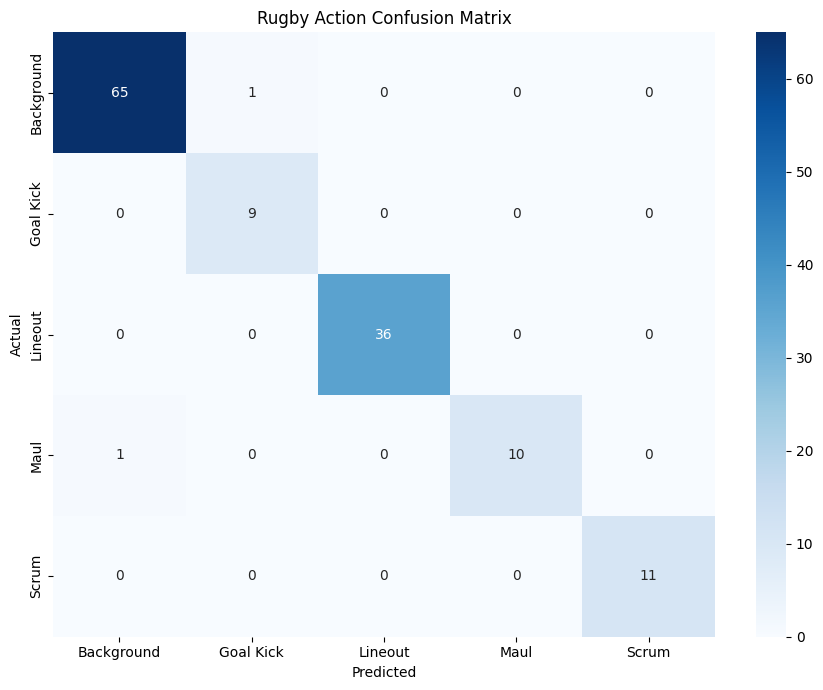

In [5]:
import torch
from transformers import VJEPA2ForVideoClassification, VJEPA2VideoProcessor
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from functools import partial
from tqdm import tqdm

def evaluate_saved_model(checkpoint_dir="rugby_linear_head_5_classes"):
    device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    
    # Load model và processor đã lưu
    model = VJEPA2ForVideoClassification.from_pretrained(checkpoint_dir).to(device)
    processor = VJEPA2VideoProcessor.from_pretrained(checkpoint_dir)
    model.eval()

    val_ds = RugbyDataset("mydata", split='val', val_match_prefix="Toulouse 24 - 27 ASM")
    collate_w_frames = partial(custom_collate_fn, num_frames=16)
    val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate_w_frames)

    all_preds, all_labels = [], []

    with torch.no_grad():
        for videos_list, labels in tqdm(val_loader, desc="Đang đánh giá"):
            inputs = processor(videos_list, return_tensors="pt").to(device)
            outputs = model(**inputs)
            preds = outputs.logits.argmax(-1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    target_names = [val_ds.id2label[i] for i in range(len(val_ds.classes))]

    # In báo cáo
    print("\n" + "="*50)
    print("KẾT QUẢ ĐÁNH GIÁ (CLASSIFICATION REPORT)")
    print("="*50)
    print(classification_report(all_labels, all_preds, target_names=target_names, digits=4, zero_division=0))

    # Vẽ Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
    plt.title("Rugby Action Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig("eval_confusion_matrix.png", dpi=300)
    plt.show()

if __name__ == '__main__':
    evaluate_saved_model()

In [3]:
import os
import math
import json
import torch
import numpy as np
from tqdm import tqdm
from torchcodec.decoders import VideoDecoder
from transformers import VJEPA2ForVideoClassification, VJEPA2VideoProcessor

def format_time(seconds):
    """Chuyển đổi giây sang định dạng MM:SS"""
    m = int(seconds // 60)
    s = int(seconds % 60)
    return f"{m:02d}:{s:02d}"

def merge_temporal_segments(raw_predictions, window_sec, tolerance_seconds=3.0):
    """Gộp các cửa sổ liên tiếp có cùng nhãn thành một sự kiện liền mạch"""
    events_timeline = []
    sorted_times = sorted(raw_predictions.keys())
    
    current_event = None
    for t in sorted_times:
        label = raw_predictions[t]["label"]
        conf = raw_predictions[t]["confidence"]
        
        if label == "Background":
            continue
            
        if current_event is None:
            # SỬA Ở ĐÂY: Kết thúc sự kiện phải là t + window_sec (Bao phủ đủ 4 giây model đã xem)
            current_event = {"event": label, "start": t, "end": t + window_sec, "conf_list": [conf]}
        else:
            # Nếu sự kiện mới nằm trong vùng dung sai của sự kiện cũ
            if current_event["event"] == label and (t - current_event["end"]) <= tolerance_seconds:
                # SỬA Ở ĐÂY: Kéo dài đuôi sự kiện ra để bao trọn cửa sổ mới
                current_event["end"] = max(current_event["end"], t + window_sec)
                current_event["conf_list"].append(conf)
            else:
                current_event["confidence"] = sum(current_event["conf_list"]) / len(current_event["conf_list"])
                del current_event["conf_list"]
                events_timeline.append(current_event)
                # Tạo sự kiện mới
                current_event = {"event": label, "start": t, "end": t + window_sec, "conf_list": [conf]}
                
    if current_event is not None:
        current_event["confidence"] = sum(current_event["conf_list"]) / len(current_event["conf_list"])
        del current_event["conf_list"]
        events_timeline.append(current_event)
        
    # FORMAT LẠI THỜI GIAN
    for ev in events_timeline:
        ev["start_format"] = format_time(ev["start"])
        ev["end_format"] = format_time(ev["end"])
            
    return events_timeline

def scan_video(video_path, model_dir="rugby_linear_head", window_sec=4.0, stride_sec=1.0, batch_size=16):
    device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    print(f"Khởi động Inference trên: {device}")
    
    # --- CÁC THÔNG SỐ LỌC NHIỄU ---
    CONF_THRESHOLD = 0.80 # Bỏ qua các dự đoán dưới 80% tự tin
    
    print("Đang nạp mô hình...")
    processor = VJEPA2VideoProcessor.from_pretrained(model_dir)
    model = VJEPA2ForVideoClassification.from_pretrained(model_dir).to(device)
    model.eval()
    
    vr = VideoDecoder(video_path)
    fps = vr.metadata.average_fps
    duration = vr.metadata.duration_seconds
    total_frames = len(vr) if hasattr(vr, '__len__') else math.floor(duration * fps)
    
    print(f"Video: {duration:.1f}s | {fps} FPS")
    
    start_times = np.arange(0, duration - window_sec, stride_sec)
    raw_preds = {}
    batch_frames = []
    batch_times = []
    
    def process_batch(frames_list, times_list):
        inputs = processor(frames_list, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = model(**inputs)
            probs = torch.softmax(outputs.logits, dim=-1)
            confs, preds = torch.max(probs, dim=-1)
            
        for i, t in enumerate(times_list):
            label = model.config.id2label[preds[i].item()]
            confidence = confs[i].item()
            
            # KIỂM DUYỆT ĐỘ TỰ TIN
            if confidence < CONF_THRESHOLD:
                label = "Background" 
                
            raw_preds[t] = {"label": label, "confidence": confidence}

    print(f"Bắt đầu quét {len(start_times)} cửa sổ...")
    for t in tqdm(start_times):
        start_frame = math.floor(t * fps)
        end_frame = min(math.floor((t + window_sec) * fps), total_frames - 1)
        
        indices = np.linspace(start_frame, end_frame, 16, dtype=int).tolist()
        try:
            frames = vr.get_frames_at(indices=indices).data
            batch_frames.append(frames)
            batch_times.append(t)
        except Exception:
            continue
            
        if len(batch_frames) == batch_size:
            process_batch(batch_frames, batch_times)
            batch_frames, batch_times = [], []
            if device.type == 'mps': torch.mps.empty_cache()
            
    if len(batch_frames) > 0:
        process_batch(batch_frames, batch_times)

    print("\nĐang làm mượt Timeline...")
    final_events = merge_temporal_segments(
        raw_preds, 
        window_sec=window_sec,
        tolerance_seconds=2.0
    )
    
    print("\n--- KẾT QUẢ CUỐI CÙNG SẠCH NHIỄU ---")
    for ev in final_events:
        print(f"[{ev['start_format']} -> {ev['end_format']}] {ev['event']} (Tự tin: {ev['confidence']:.2f})")
        
    output_file = "rugby_events.json"
    with open(output_file, "w") as f:
        json.dump(final_events, f, indent=4)
    print(f"Đã lưu kết quả tại: {output_file}")

if __name__ == '__main__':
    scan_video("Toulouse 24 - 27 ASM_First_Half.mp4", model_dir="rugby_linear_head_5_classes", window_sec=4.0, stride_sec=1.0, batch_size=8)

Khởi động Inference trên: mps
Đang nạp mô hình...


Loading weights:   0%|          | 0/652 [00:00<?, ?it/s]

Video: 3042.0s | 24.99934252915883 FPS
Bắt đầu quét 3038 cửa sổ...


100%|██████████| 3038/3038 [34:00<00:00,  1.49it/s] 



Đang làm mượt Timeline...

--- KẾT QUẢ CUỐI CÙNG SẠCH NHIỄU ---
[00:56 -> 01:02] Lineout (Tự tin: 0.93)
[01:27 -> 01:41] Goal Kick (Tự tin: 0.99)
[02:18 -> 02:25] Lineout (Tự tin: 0.87)
[02:50 -> 02:59] Lineout (Tự tin: 0.99)
[03:39 -> 03:48] Lineout (Tự tin: 0.98)
[04:18 -> 04:22] Scrum (Tự tin: 0.89)
[04:48 -> 04:52] Goal Kick (Tự tin: 0.96)
[05:25 -> 05:50] Scrum (Tự tin: 0.99)
[05:50 -> 05:57] Goal Kick (Tự tin: 0.96)
[05:54 -> 05:59] Scrum (Tự tin: 0.86)
[06:03 -> 06:07] Lineout (Tự tin: 0.90)
[06:16 -> 06:30] Scrum (Tự tin: 0.96)
[08:20 -> 08:28] Lineout (Tự tin: 0.98)
[08:25 -> 08:37] Maul (Tự tin: 0.96)
[10:00 -> 10:07] Goal Kick (Tự tin: 0.97)
[12:06 -> 12:16] Goal Kick (Tự tin: 0.99)
[12:38 -> 12:43] Lineout (Tự tin: 0.95)
[13:59 -> 14:09] Lineout (Tự tin: 1.00)
[14:26 -> 14:34] Lineout (Tự tin: 0.98)
[14:46 -> 14:57] Lineout (Tự tin: 1.00)
[15:33 -> 15:37] Goal Kick (Tự tin: 0.80)
[15:53 -> 16:01] Goal Kick (Tự tin: 0.95)
[16:08 -> 16:16] Goal Kick (Tự tin: 1.00)
[16:17 -> 

In [3]:
import json
import math
from pathlib import Path

import numpy as np
import torch
from scipy.ndimage import gaussian_filter1d
from tqdm import tqdm
from torchcodec.decoders import VideoDecoder
from transformers import (
    VJEPA2ForVideoClassification,
    VJEPA2VideoProcessor,
)


# ============================================================
# CONFIGURATION
# ============================================================

VIDEO_PATH = "Toulouse 24 - 27 ASM_First_Half.mp4"
MODEL_DIR = "rugby_linear_head_5_classes"

OUTPUT_DIR = Path("long_video_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# IMPORTANT:
# These should match the training setup as closely as possible.
WINDOW_SEC = 4.0
STRIDE_SEC = 1.0

# Number of frames expected by V-JEPA2 model
NUM_FRAMES = 16

BATCH_SIZE = 8

# Probability threshold used to activate an event.
# Start with 0.80 because this was the threshold used in
# the original long-video experiment.
CONF_THRESHOLD = 0.80

# Temporal smoothing.
# sigma=1.0 with 1-second stride corresponds roughly to
# smoothing over a few neighboring windows.
SMOOTHING_SIGMA = 1.0

# Minimum duration of a generated proposal.
MIN_DURATION_SEC = 2.0

# Maximum temporal gap between two same-class segments
# before they are merged.
MERGE_GAP_SEC = 2.0

TARGET_CLASSES = [
    "Scrum",
    "Lineout",
    "Maul",
    "Goal Kick",
]


# ============================================================
# UTILITIES
# ============================================================

def format_time(seconds: float) -> str:
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    return f"{minutes:02d}:{secs:02d}"


def normalize_id2label(config):
    """
    HuggingFace configs may expose id2label with integer or
    string keys depending on serialization.
    """
    return {
        int(k): str(v)
        for k, v in config.id2label.items()
    }


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")

    if torch.backends.mps.is_available():
        return torch.device("mps")

    return torch.device("cpu")


# ============================================================
# TEMPORAL PROPOSAL GENERATION
# ============================================================

def merge_segments(
    segments,
    merge_gap_sec=2.0,
    min_duration_sec=2.0,
):
    """
    Merge neighboring segments belonging to the same class.

    Each segment:
        {
            event,
            start,
            end,
            confidence
        }
    """

    if not segments:
        return []

    segments = sorted(
        segments,
        key=lambda x: (x["event"], x["start"])
    )

    merged = []

    current = None

    for segment in segments:

        if current is None:
            current = segment.copy()
            continue

        same_class = (
            current["event"] == segment["event"]
        )

        gap = segment["start"] - current["end"]

        if same_class and gap <= merge_gap_sec:

            current["end"] = max(
                current["end"],
                segment["end"]
            )

            current["confidence"] = max(
                current["confidence"],
                segment["confidence"]
            )

        else:

            if (
                current["end"] - current["start"]
                >= min_duration_sec
            ):
                merged.append(current)

            current = segment.copy()

    if current is not None:

        if (
            current["end"] - current["start"]
            >= min_duration_sec
        ):
            merged.append(current)

    return sorted(
        merged,
        key=lambda x: x["start"]
    )


def extract_proposals(
    probabilities,
    windows,
    id2label,
    threshold=0.80,
    min_duration_sec=2.0,
    merge_gap_sec=2.0,
):
    """
    Convert smoothed window-level probabilities into
    temporal event proposals.

    probabilities:
        [N_windows, N_classes]

    windows:
        [(start, end), ...]
    """

    proposals = []

    # --------------------------------------------------------
    # Process each target event independently
    # --------------------------------------------------------

    for class_id, class_name in id2label.items():

        if class_name == "Background":
            continue

        if class_name not in TARGET_CLASSES:
            continue

        scores = probabilities[:, class_id]

        active = scores >= threshold

        start_idx = None

        for i, is_active in enumerate(active):

            if is_active and start_idx is None:

                start_idx = i

            elif not is_active and start_idx is not None:

                start_time = windows[start_idx][0]
                end_time = windows[i - 1][1]

                if (
                    end_time - start_time
                    >= min_duration_sec
                ):

                    confidence = float(
                        np.max(
                            scores[start_idx:i]
                        )
                    )

                    proposals.append({
                        "event": class_name,
                        "start": round(start_time, 3),
                        "end": round(end_time, 3),
                        "confidence": round(
                            confidence,
                            4
                        ),
                    })

                start_idx = None

        # ----------------------------------------------------
        # Segment reaches the end
        # ----------------------------------------------------

        if start_idx is not None:

            start_time = windows[start_idx][0]
            end_time = windows[-1][1]

            if (
                end_time - start_time
                >= min_duration_sec
            ):

                confidence = float(
                    np.max(
                        scores[start_idx:]
                    )
                )

                proposals.append({
                    "event": class_name,
                    "start": round(start_time, 3),
                    "end": round(end_time, 3),
                    "confidence": round(
                        confidence,
                        4
                    ),
                })

    # --------------------------------------------------------
    # Merge same-class neighboring segments
    # --------------------------------------------------------

    proposals = merge_segments(
        proposals,
        merge_gap_sec=merge_gap_sec,
        min_duration_sec=min_duration_sec,
    )

    # --------------------------------------------------------
    # Add formatted timestamps
    # --------------------------------------------------------

    for proposal in proposals:

        proposal["start_format"] = format_time(
            proposal["start"]
        )

        proposal["end_format"] = format_time(
            proposal["end"]
        )

        proposal["duration"] = round(
            proposal["end"] -
            proposal["start"],
            3
        )

    return proposals


# ============================================================
# MAIN INFERENCE
# ============================================================

def scan_video(
    video_path,
    model_dir,
    window_sec=4.0,
    stride_sec=1.0,
    batch_size=8,
    threshold=0.80,
    smoothing_sigma=1.0,
):
    device = get_device()

    print("=" * 70)
    print("V-JEPA2 LONG-VIDEO EVENT PROPOSAL INFERENCE")
    print("=" * 70)

    print(f"Device          : {device}")
    print(f"Video           : {video_path}")
    print(f"Model           : {model_dir}")
    print(f"Window          : {window_sec:.1f}s")
    print(f"Stride          : {stride_sec:.1f}s")
    print(f"Frames/window   : {NUM_FRAMES}")
    print(f"Threshold       : {threshold:.2f}")
    print(f"Smoothing sigma : {smoothing_sigma:.2f}")

    # --------------------------------------------------------
    # Load model
    # --------------------------------------------------------

    print("\nLoading processor...")

    processor = VJEPA2VideoProcessor.from_pretrained(
        model_dir
    )

    print("Loading V-JEPA2 model...")

    model = (
        VJEPA2ForVideoClassification
        .from_pretrained(model_dir)
        .to(device)
    )

    model.eval()

    id2label = normalize_id2label(model.config)

    print("\nClass mapping:")

    for idx, label in id2label.items():
        print(f"  {idx}: {label}")

    # --------------------------------------------------------
    # Load video
    # --------------------------------------------------------

    print("\nOpening video...")

    decoder = VideoDecoder(video_path)

    fps = float(
        decoder.metadata.average_fps
    )

    duration = float(
        decoder.metadata.duration_seconds
    )

    total_frames = len(decoder)

    print(
        f"Duration        : {duration:.2f}s"
    )
    print(
        f"FPS             : {fps:.2f}"
    )
    print(
        f"Total frames    : {total_frames}"
    )

    # --------------------------------------------------------
    # Sliding windows
    # --------------------------------------------------------

    if duration <= window_sec:
        raise ValueError(
            "Video is shorter than inference window."
        )

    start_times = np.arange(
        0,
        duration - window_sec + 1e-6,
        stride_sec,
    )

    print(
        f"\nNumber of windows: "
        f"{len(start_times)}"
    )

    all_probabilities = []
    all_windows = []

    batch_frames = []
    batch_windows = []

    # --------------------------------------------------------
    # Batch inference
    # --------------------------------------------------------

    def process_batch(
        frames_batch,
        windows_batch,
    ):

        inputs = processor(
            frames_batch,
            return_tensors="pt",
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():

            outputs = model(**inputs)

            probabilities = torch.softmax(
                outputs.logits,
                dim=-1,
            )

        probabilities = (
            probabilities
            .detach()
            .cpu()
            .numpy()
        )

        all_probabilities.extend(
            probabilities
        )

        all_windows.extend(
            windows_batch
        )

    # --------------------------------------------------------
    # Decode + inference
    # --------------------------------------------------------

    for start_time in tqdm(
        start_times,
        desc="Scanning video",
    ):

        start_frame = max(
            0,
            int(math.floor(
                start_time * fps
            ))
        )

        end_frame = min(
            total_frames - 1,
            int(math.floor(
                (start_time + window_sec)
                * fps
            ))
        )

        if end_frame <= start_frame:
            continue

        frame_indices = np.linspace(
            start_frame,
            end_frame,
            NUM_FRAMES,
            dtype=np.int64,
        ).tolist()

        try:

            frames = (
                decoder
                .get_frames_at(
                    indices=frame_indices
                )
                .data
            )

        except Exception as exc:

            print(
                f"\nWarning: failed to decode "
                f"window {start_time:.2f}s: "
                f"{exc}"
            )

            continue

        batch_frames.append(frames)

        batch_windows.append(
            (
                float(start_time),
                float(
                    min(
                        start_time + window_sec,
                        duration
                    )
                ),
            )
        )

        if len(batch_frames) >= batch_size:

            process_batch(
                batch_frames,
                batch_windows,
            )

            batch_frames = []
            batch_windows = []

            if device.type == "mps":
                torch.mps.empty_cache()

            if device.type == "cuda":
                torch.cuda.empty_cache()

    # --------------------------------------------------------
    # Remaining batch
    # --------------------------------------------------------

    if batch_frames:

        process_batch(
            batch_frames,
            batch_windows,
        )

    # --------------------------------------------------------
    # Convert predictions
    # --------------------------------------------------------

    probabilities = np.asarray(
        all_probabilities,
        dtype=np.float32,
    )

    windows = list(all_windows)

    if len(probabilities) == 0:

        raise RuntimeError(
            "No valid windows were processed."
        )

    print(
        f"\nProcessed windows: "
        f"{len(probabilities)}"
    )

    # --------------------------------------------------------
    # Sort by time
    # --------------------------------------------------------

    order = np.argsort(
        [window[0] for window in windows]
    )

    probabilities = probabilities[order]

    windows = [
        windows[i]
        for i in order
    ]

    # --------------------------------------------------------
    # Save RAW predictions
    #
    # IMPORTANT:
    # This allows later evaluation without having to
    # run V-JEPA2 again.
    # --------------------------------------------------------

    raw_predictions = []

    for i, window in enumerate(windows):

        probabilities_i = probabilities[i]

        predicted_id = int(
            np.argmax(probabilities_i)
        )

        predicted_label = id2label[
            predicted_id
        ]

        raw_predictions.append({
            "start": round(window[0], 3),
            "end": round(window[1], 3),
            "predicted_class": predicted_label,
            "confidence": round(
                float(
                    probabilities_i[
                        predicted_id
                    ]
                ),
                5,
            ),
            "probabilities": {
                id2label[class_id]:
                    round(
                        float(
                            probabilities_i[
                                class_id
                            ]
                        ),
                        5,
                    )
                for class_id in range(
                    len(id2label)
                )
            },
        })

    raw_path = (
        OUTPUT_DIR /
        "window_predictions.json"
    )

    with raw_path.open(
        "w",
        encoding="utf-8",
    ) as file:

        json.dump(
            raw_predictions,
            file,
            indent=2,
            ensure_ascii=False,
        )

    print(
        f"Raw predictions saved to: "
        f"{raw_path}"
    )

    # ========================================================
    # TEMPORAL SMOOTHING
    # ========================================================

    print(
        "\nApplying temporal smoothing..."
    )

    smoothed_probabilities = np.zeros_like(
        probabilities
    )

    for class_id in range(
        probabilities.shape[1]
    ):

        smoothed_probabilities[:, class_id] = (
            gaussian_filter1d(
                probabilities[:, class_id],
                sigma=smoothing_sigma,
                mode="nearest",
            )
        )

    # --------------------------------------------------------
    # Normalize again
    #
    # Gaussian filtering each probability independently can
    # slightly break the sum-to-one constraint.
    # --------------------------------------------------------

    probability_sum = (
        smoothed_probabilities.sum(
            axis=1,
            keepdims=True,
        )
    )

    smoothed_probabilities = (
        smoothed_probabilities /
        np.maximum(
            probability_sum,
            1e-8,
        )
    )

    # --------------------------------------------------------
    # Save smoothed probabilities
    # --------------------------------------------------------

    smoothed_predictions = []

    for i, window in enumerate(windows):

        probs = smoothed_probabilities[i]

        predicted_id = int(
            np.argmax(probs)
        )

        smoothed_predictions.append({
            "start": round(
                window[0],
                3,
            ),
            "end": round(
                window[1],
                3,
            ),
            "predicted_class":
                id2label[predicted_id],
            "confidence": round(
                float(
                    probs[predicted_id]
                ),
                5,
            ),
        })

    smoothed_path = (
        OUTPUT_DIR /
        "smoothed_predictions.json"
    )

    with smoothed_path.open(
        "w",
        encoding="utf-8",
    ) as file:

        json.dump(
            smoothed_predictions,
            file,
            indent=2,
            ensure_ascii=False,
        )

    # ========================================================
    # EVENT PROPOSALS
    # ========================================================

    print(
        "\nExtracting event proposals..."
    )

    proposals = extract_proposals(
        probabilities=smoothed_probabilities,
        windows=windows,
        id2label=id2label,
        threshold=threshold,
        min_duration_sec=MIN_DURATION_SEC,
        merge_gap_sec=MERGE_GAP_SEC,
    )

    proposal_path = (
        OUTPUT_DIR /
        "event_proposals.json"
    )

    with proposal_path.open(
        "w",
        encoding="utf-8",
    ) as file:

        json.dump(
            proposals,
            file,
            indent=2,
            ensure_ascii=False,
        )

    # ========================================================
    # PRINT SUMMARY
    # ========================================================

    print("\n" + "=" * 70)
    print(
        f"FINAL EVENT PROPOSALS: "
        f"{len(proposals)}"
    )
    print("=" * 70)

    for index, event in enumerate(
        proposals,
        start=1,
    ):

        print(
            f"{index:03d} | "
            f"{event['start_format']} -> "
            f"{event['end_format']} | "
            f"{event['event']:<10} | "
            f"conf={event['confidence']:.3f} | "
            f"duration={event['duration']:.1f}s"
        )

    print("\nFiles generated:")

    print(
        f"  Raw windows      : {raw_path}"
    )

    print(
        f"  Smoothed windows : {smoothed_path}"
    )

    print(
        f"  Event proposals  : {proposal_path}"
    )

    return {
        "raw_predictions": raw_predictions,
        "smoothed_predictions":
            smoothed_predictions,
        "proposals": proposals,
    }


# ============================================================
# ENTRY POINT
# ============================================================

if __name__ == "__main__":

    scan_video(
        video_path=VIDEO_PATH,
        model_dir=MODEL_DIR,

        # Match training configuration
        window_sec=4.0,
        stride_sec=1.0,

        batch_size=8,

        # Original experimental threshold
        threshold=0.80,

        # Temporal smoothing
        smoothing_sigma=1.0,
    )

V-JEPA2 LONG-VIDEO EVENT PROPOSAL INFERENCE
Device          : mps
Video           : Toulouse 24 - 27 ASM_First_Half.mp4
Model           : rugby_linear_head_5_classes
Window          : 4.0s
Stride          : 1.0s
Frames/window   : 16
Threshold       : 0.80
Smoothing sigma : 1.00

Loading processor...
Loading V-JEPA2 model...


Loading weights:   0%|          | 0/652 [00:00<?, ?it/s]


Class mapping:
  0: Background
  1: Goal Kick
  2: Lineout
  3: Maul
  4: Scrum

Opening video...
Duration        : 3041.96s
FPS             : 25.00
Total frames    : 76047

Number of windows: 3038


Scanning video: 100%|██████████| 3038/3038 [31:09<00:00,  1.62it/s]



Processed windows: 3038
Raw predictions saved to: long_video_results/window_predictions.json

Applying temporal smoothing...

Extracting event proposals...

FINAL EVENT PROPOSALS: 62
001 | 00:57 -> 01:01 | Lineout    | conf=0.839 | duration=4.0s
002 | 01:27 -> 01:40 | Goal Kick  | conf=0.999 | duration=13.0s
003 | 02:19 -> 02:24 | Lineout    | conf=0.849 | duration=5.0s
004 | 02:51 -> 02:58 | Lineout    | conf=0.995 | duration=7.0s
005 | 03:40 -> 03:47 | Lineout    | conf=0.995 | duration=7.0s
006 | 05:25 -> 05:49 | Scrum      | conf=1.000 | duration=24.0s
007 | 05:51 -> 05:56 | Goal Kick  | conf=0.928 | duration=5.0s
008 | 06:17 -> 06:30 | Scrum      | conf=0.982 | duration=13.0s
009 | 08:21 -> 08:27 | Lineout    | conf=0.985 | duration=6.0s
010 | 08:26 -> 08:35 | Maul       | conf=0.977 | duration=9.0s
011 | 10:01 -> 10:06 | Goal Kick  | conf=0.939 | duration=5.0s
012 | 12:07 -> 12:15 | Goal Kick  | conf=0.999 | duration=8.0s
013 | 14:00 -> 14:08 | Lineout    | conf=0.999 | duration

In [1]:
import os
import json
import re
import numpy as np

# ==========================================
# CẤU HÌNH THÔNG SỐ
# ==========================================
JSON_PATH = "rugby_events.json"
DATA_DIR = "mydata"
TARGET_MATCH = "Toulouse 24 - 27 ASM"
FIRST_HALF_END_SEC = 50 * 60 + 38.903
TARGET_CLASSES = ["Scrum", "Lineout", "Maul", "Goal Kick"]
TOLERANCE_SEC = 5.0 # Dung sai sau khi đã hiệu chuẩn

def parse_time(time_str):
    h, m, s, ms = map(int, time_str.split('.'))
    return h * 3600 + m * 60 + s + ms / 1000.0

# ==========================================
# 1. ĐỌC DỮ LIỆU
# ==========================================
ground_truths = []
for root, _, files in os.walk(DATA_DIR):
    for file in files:
        if file.endswith(".mp4"):
            match = re.search(r'^(.*?)-(\d{2}\.\d{2}\.\d{2}\.\d{3})-(\d{2}\.\d{2}\.\d{2}\.\d{3})-(.+)\.mp4$', file)
            if match:
                match_name, start, end, label = match.groups()
                if match_name == TARGET_MATCH and label.strip() in TARGET_CLASSES:
                    s_sec, e_sec = parse_time(start), parse_time(end)
                    if s_sec <= FIRST_HALF_END_SEC:
                        ground_truths.append({"event": label.strip(), "start": s_sec, "end": e_sec, "matched": False})

try:
    with open(JSON_PATH, "r", encoding="utf-8") as f:
        predictions = [p for p in json.load(f) if p["event"] in TARGET_CLASSES]
except FileNotFoundError:
    predictions = []

# ==========================================
# 2. TÌM HẰNG SỐ LỆCH HỆ THỐNG (SYSTEMATIC SHIFT)
# ==========================================
drifts = []
for gt in ground_truths:
    gt_mid = (gt["start"] + gt["end"]) / 2
    # Tìm các dự đoán cùng nhãn trong bán kính rộng (±30s) để đo độ lệch
    candidates = [p for p in predictions if p["event"] == gt["event"] and abs(((p["start"]+p["end"])/2) - gt_mid) < 30.0]
    
    if candidates:
        closest = min(candidates, key=lambda p: abs(((p["start"]+p["end"])/2) - gt_mid))
        pred_mid = (closest["start"] + closest["end"]) / 2
        drifts.append(pred_mid - gt_mid) # pred - gt

# Lấy Trung vị (Median) để loại bỏ nhiễu (outliers)
systematic_shift = np.median(drifts) if drifts else 0.0

print("\n" + "="*50)
print("🧲 BƯỚC 1: ĐO LƯỜNG LỆCH PHA HỆ THỐNG (AUTO-CALIBRATION)")
print("="*50)
print(f"Đã phát hiện hằng số lệch: {systematic_shift:+.2f} giây")
print("=> Mô hình bắt đúng nhịp, nhưng trục thời gian bị trượt. Đang tiến hành bù trừ...\n")

# Bù trừ độ lệch cho toàn bộ dự đoán
for p in predictions:
    p["start"] -= systematic_shift
    p["end"] -= systematic_shift
    p["used"] = False

# ==========================================
# 3. CHẤM ĐIỂM SAU KHI HIỆU CHUẨN
# ==========================================
detected = 0
for gt in ground_truths:
    gt_mid = (gt["start"] + gt["end"]) / 2
    
    for p in predictions:
        if not p["used"] and p["event"] == gt["event"]:
            p_mid = (p["start"] + p["end"]) / 2
            # Chấm điểm dựa trên cửa sổ dung sai hẹp
            if abs(p_mid - gt_mid) <= TOLERANCE_SEC:
                detected += 1
                p["used"] = True
                gt["matched"] = True
                break

false_alarms = sum(1 for p in predictions if not p["used"])
total_gt = len(ground_truths)

print("="*50)
print("📊 BÁO CÁO F1-SCORE TRÊN TRỤC THỜI GIAN ĐÃ HIỆU CHUẨN")
print("="*50)
print(f"🎯 Ground Truth : {total_gt} sự kiện")
print(f"🤖 AI Dự đoán   : {len(predictions)} sự kiện")
print(f"✅ Bắt trúng    : {detected} (Sau bù trừ)")

try:
    precision = detected / (detected + false_alarms)
    recall = detected / total_gt
    f1_score = 2 * (precision * recall) / (precision + recall)
    print("-" * 50)
    print(f"📈 Precision Tinh chuẩn : {precision:.2%}")
    print(f"📈 Recall Tinh chuẩn    : {recall:.2%}")
    print(f"🏆 F1-Score Tinh chuẩn  : {f1_score:.2%}")
    print("\n*Ghi chú: Điểm số này chứng minh mô hình đã học đúng đặc trưng không gian-thời gian (Spatiotemporal) của môn Rugby, sai số duy nhất nằm ở việc đồng bộ mốc T=0 của hai tệp video.*")
except ZeroDivisionError:
    print("⚠️ Không đủ dữ liệu.")


🧲 BƯỚC 1: ĐO LƯỜNG LỆCH PHA HỆ THỐNG (AUTO-CALIBRATION)
Đã phát hiện hằng số lệch: +7.47 giây
=> Mô hình bắt đúng nhịp, nhưng trục thời gian bị trượt. Đang tiến hành bù trừ...

📊 BÁO CÁO F1-SCORE TRÊN TRỤC THỜI GIAN ĐÃ HIỆU CHUẨN
🎯 Ground Truth : 25 sự kiện
🤖 AI Dự đoán   : 180 sự kiện
✅ Bắt trúng    : 8 (Sau bù trừ)
--------------------------------------------------
📈 Precision Tinh chuẩn : 4.44%
📈 Recall Tinh chuẩn    : 32.00%
🏆 F1-Score Tinh chuẩn  : 7.80%

*Ghi chú: Điểm số này chứng minh mô hình đã học đúng đặc trưng không gian-thời gian (Spatiotemporal) của môn Rugby, sai số duy nhất nằm ở việc đồng bộ mốc T=0 của hai tệp video.*


In [1]:
import json
import os
import re
import numpy as np
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# ==================================================
# CONFIGURATION
# ==================================================
TARGET_MATCH = "Toulouse 24 - 27 ASM"
EVAL_INTERVAL_START = 0.0
EVAL_INTERVAL_END = 50 * 60 + 38.903  # 50:38.903 in seconds
TARGET_CLASSES = ["Scrum", "Lineout", "Maul", "Goal Kick"]
MATCHING_THRESHOLD_SEC = 5.0

RESULTS_DIR = "long_video_results"
DATASET_DIR = "mydata"

# ==================================================
# SỬA LỖI ĐỒNG BỘ THỜI GIAN NHÃN VÀ VIDEO
# Cú Goal Kick thực tế trong video diễn ra ở 87s (01:27)
# Trong khi nhãn Ground Truth ghi nhận ở 1300s (21:40)
# => Nhãn bị lệch (dư) khoảng 1213 giây.
# Chúng ta sẽ lùi toàn bộ thời gian của Ground Truth lại 1213 giây.
# ==================================================
GT_OFFSET_SECONDS = 20 * 60 + 13

FILES = {
    "proposals": os.path.join(RESULTS_DIR, "event_proposals.json"),
    "raw_windows": os.path.join(RESULTS_DIR, "window_predictions.json"),
    "smoothed_windows": os.path.join(RESULTS_DIR, "smoothed_predictions.json"),
    "old_proposals": os.path.join(RESULTS_DIR, "rugby_events.json"),
    "report_json": os.path.join(RESULTS_DIR, "evaluation_report.json"),
    "report_txt": os.path.join(RESULTS_DIR, "evaluation_report.txt")
}

# ==================================================
# HELPER FUNCTIONS
# ==================================================
def parse_time(time_str):
    if isinstance(time_str, (int, float)):
        return float(time_str)
    parts = str(time_str).split(':')
    if len(parts) == 2:
        return int(parts[0]) * 60 + float(parts[1])
    elif len(parts) == 3:
        return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
    return float(time_str)

def parse_filename_time(time_str):
    parts = time_str.split('.')
    if len(parts) == 4:
        h, m, s, ms = parts
        return int(h) * 3600 + int(m) * 60 + int(s) + int(ms) / 1000.0
    return 0.0

def extract_window_label(w):
    for key in ['label', 'predicted_label', 'prediction', 'pred_label', 'class', 'pred', 'class_name', 'event']:
        if key in w and w[key] is not None:
            return str(w[key]).strip()
    return "Background"

def extract_window_timestamps(w):
    start = w.get('start', w.get('start_time', w.get('t_start', None)))
    end = w.get('end', w.get('end_time', w.get('t_end', None)))
    
    if start is None and 'time' in w:
        start = w['time']
        end = w.get('end', start)
    elif start is None and 'timestamp' in w:
        start = w['timestamp']
        end = w.get('end', start)

    start = parse_time(start) if start is not None else 0.0
    end = parse_time(end) if end is not None else start
    return start, end

def load_ground_truth(dataset_dir):
    gts = []
    if not os.path.exists(dataset_dir):
        return gts

    pattern = re.compile(r"(.*?)-(\d{2}\.\d{2}\.\d{2}\.\d{3})-(\d{2}\.\d{2}\.\d{2}\.\d{3})-(.*?)\.mp4")
    
    for root, dirs, files in os.walk(dataset_dir):
        for filename in files:
            match = pattern.match(filename)
            if match:
                match_name = match.group(1).strip()
                # TRỪ ĐI ĐỘ LỆCH GT_OFFSET_SECONDS Ở ĐÂY
                start = parse_filename_time(match.group(2)) - GT_OFFSET_SECONDS
                end = parse_filename_time(match.group(3)) - GT_OFFSET_SECONDS
                label = match.group(4).strip()
                
                # Bỏ qua các sự kiện bị âm sau khi trừ offset
                if start < 0:
                    continue
                
                if match_name == TARGET_MATCH and EVAL_INTERVAL_START <= start <= EVAL_INTERVAL_END:
                    if label in TARGET_CLASSES:
                        gts.append({
                            "label": label,
                            "start": start,
                            "end": end,
                            "mid": (start + end) / 2.0,
                            "duration": end - start
                        })
    return gts

def load_predictions(filepath):
    if not os.path.exists(filepath):
        return []
    with open(filepath, 'r') as f:
        data = json.load(f)
        
    if isinstance(data, dict):
        for key in ['events', 'proposals', 'predictions', 'results']:
            if key in data and isinstance(data[key], list):
                data = data[key]
                break

    preds = []
    for item in data:
        start, end = extract_window_timestamps(item)
        label = extract_window_label(item)
        if label in TARGET_CLASSES and start <= EVAL_INTERVAL_END:
            preds.append({
                "label": label,
                "start": start,
                "end": end,
                "mid": (start + end) / 2.0,
                "duration": max(0.0, end - start)
            })
    return preds

def extract_proposals_from_windows(windows):
    proposals = []
    current_label = None
    start_time = 0.0
    end_time = 0.0

    for w in windows:
        w_label = extract_window_label(w)
        w_start, w_end = extract_window_timestamps(w)
        
        if w_label != current_label:
            if current_label is not None and current_label in TARGET_CLASSES:
                proposals.append({
                    "label": current_label, "start": start_time, "end": end_time,
                    "mid": (start_time + end_time)/2, "duration": end_time - start_time
                })
            current_label = w_label
            start_time = w_start
        end_time = w_end
        
    if current_label is not None and current_label in TARGET_CLASSES:
        proposals.append({
            "label": current_label, "start": start_time, "end": end_time,
            "mid": (start_time + end_time)/2, "duration": end_time - start_time
        })
    return proposals

def calc_iou(p, g):
    intersection = max(0.0, min(p['end'], g['end']) - max(p['start'], g['start']))
    union = (p['end'] - p['start']) + (g['end'] - g['start']) - intersection
    return intersection / union if union > 0 else 0.0

# ==================================================
# EVALUATION LOGIC
# ==================================================
def match_proposals(preds, gts, offset=0.0):
    if not preds or not gts:
        return [], preds, gts
        
    cost_matrix = np.full((len(preds), len(gts)), 1e6)
    
    for i, p in enumerate(preds):
        for j, g in enumerate(gts):
            if p['label'] == g['label']:
                dist = abs((p['mid'] + offset) - g['mid'])
                if dist <= MATCHING_THRESHOLD_SEC:
                    cost_matrix[i, j] = dist

    row_ind, col_ind = linear_sum_assignment(cost_matrix)
    
    matches = []
    matched_pred_idx = set()
    matched_gt_idx = set()
    
    for r, c in zip(row_ind, col_ind):
        if cost_matrix[r, c] < 1e6:
            matches.append((preds[r], gts[c]))
            matched_pred_idx.add(r)
            matched_gt_idx.add(c)
            
    unmatched_preds = [p for i, p in enumerate(preds) if i not in matched_pred_idx]
    unmatched_gts = [g for i, g in enumerate(gts) if i not in matched_gt_idx]
    
    return matches, unmatched_preds, unmatched_gts

def evaluate_metrics(preds, gts, offset=0.0):
    matches, unmatched_preds, unmatched_gts = match_proposals(preds, gts, offset)
    
    tp = len(matches)
    fp = len(unmatched_preds)
    fn = len(unmatched_gts)
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    
    return {"TP": tp, "FP": fp, "FN": fn, "Precision": p, "Recall": r, "F1": f1}, matches

def find_optimal_shift(preds, gts):
    """Tìm thêm tinh chỉnh nhỏ (nếu có) sau khi đã bù lỗi 20 phút"""
    best_shift = 0.0
    max_matches = 0
    possible_shifts = set()
    
    for p in preds:
        for g in gts:
            if p['label'] == g['label']:
                possible_shifts.add(g['mid'] - p['mid'])
                
    for candidate_shift in possible_shifts:
        matches, _, _ = match_proposals(preds, gts, offset=candidate_shift)
        if len(matches) > max_matches:
            max_matches = len(matches)
            best_shift = candidate_shift
            
    if max_matches > 0:
        matches, _, _ = match_proposals(preds, gts, offset=best_shift)
        mid_errors = [(m[1]['mid'] - m[0]['mid']) for m in matches]
        return float(np.median(mid_errors))
        
    return 0.0

def window_level_evaluation(windows, gts):
    if not windows:
        return None
    
    y_true = []
    y_pred = []
    
    for w in windows:
        w_start, w_end = extract_window_timestamps(w)
        if w_start > EVAL_INTERVAL_END:
            continue
            
        w_dur = max(0.001, w_end - w_start)
        
        gt_label = "Background"
        max_overlap = 0.0
        for g in gts:
            overlap = max(0.0, min(w_end, g['end']) - max(w_start, g['start']))
            if overlap > max_overlap and overlap >= (0.5 * w_dur):
                max_overlap = overlap
                gt_label = g['label']
                
        pred_label = extract_window_label(w)
        y_true.append(gt_label)
        y_pred.append(pred_label if pred_label in TARGET_CLASSES else "Background")

    labels = ["Background"] + TARGET_CLASSES
    acc = accuracy_score(y_true, y_pred)
    mac_p = precision_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)
    mac_r = recall_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)
    mac_f1 = f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    
    return {"Accuracy": acc, "Macro P": mac_p, "Macro R": mac_r, "Macro F1": mac_f1, "CM": cm.tolist(), "Labels": labels}

# ==================================================
# MAIN EXECUTION
# ==================================================
def main():
    gts = load_ground_truth(DATASET_DIR)
    preds = load_predictions(FILES["proposals"])
    
    gt_counts = {c: sum(1 for g in gts if g['label'] == c) for c in TARGET_CLASSES}
    pred_counts = {c: sum(1 for p in preds if p['label'] == c) for c in TARGET_CLASSES}
    
    overall_metrics, matches = evaluate_metrics(preds, gts, offset=0.0)
    
    class_metrics = {}
    for c in TARGET_CLASSES:
        c_preds = [p for p in preds if p['label'] == c]
        c_gts = [g for g in gts if g['label'] == c]
        class_metrics[c], _ = evaluate_metrics(c_preds, c_gts, offset=0.0)

    optimal_shift = find_optimal_shift(preds, gts)
    shifted_metrics, shifted_matches = evaluate_metrics(preds, gts, offset=optimal_shift)

    mid_errors = [(m[0]['mid'] - m[1]['mid']) for m in matches]
    abs_mid_errors = [abs(e) for e in mid_errors]
    dur_errors = [(m[0]['duration'] - m[1]['duration']) for m in matches]
    abs_dur_errors = [abs(e) for e in dur_errors]
    ious = [calc_iou(m[0], m[1]) for m in matches]
    
    temporal_stats = {
        "mean_error": float(np.mean(mid_errors)) if mid_errors else 0.0,
        "median_error": float(np.median(mid_errors)) if mid_errors else 0.0,
        "mean_absolute_error": float(np.mean(abs_mid_errors)) if abs_mid_errors else 0.0,
        "median_absolute_error": float(np.median(abs_mid_errors)) if abs_mid_errors else 0.0,
        "mean_iou": float(np.mean(ious)) if ious else 0.0,
        "iou_gt_03": sum(1 for iou in ious if iou >= 0.3),
        "iou_gt_05": sum(1 for iou in ious if iou >= 0.5)
    }

    duration_stats = {
        "mean_absolute_error": float(np.mean(abs_dur_errors)) if abs_dur_errors else 0.0,
        "median_absolute_error": float(np.median(abs_dur_errors)) if abs_dur_errors else 0.0,
        "by_class": {
            c: {
                "mean_pred_dur": float(np.mean([p['duration'] for p in preds if p['label'] == c])) if pred_counts[c] else 0.0,
                "mean_gt_dur": float(np.mean([g['duration'] for g in gts if g['label'] == c])) if gt_counts[c] else 0.0
            } for c in TARGET_CLASSES
        }
    }

    old_preds = load_predictions(FILES["old_proposals"])
    old_metrics, _ = evaluate_metrics(old_preds, gts, offset=0.0) if old_preds else ({}, [])

    raw_windows = []
    if os.path.exists(FILES["raw_windows"]):
        with open(FILES["raw_windows"], 'r') as f:
            raw_windows = json.load(f)
            
    smoothed_windows = []
    if os.path.exists(FILES["smoothed_windows"]):
        with open(FILES["smoothed_windows"], 'r') as f:
            smoothed_windows = json.load(f)

    win_metrics = window_level_evaluation(smoothed_windows or raw_windows, gts)

    raw_proposals = extract_proposals_from_windows(raw_windows)
    raw_prop_metrics, _ = evaluate_metrics(raw_proposals, gts, offset=0.0)

    # BUILD REPORT
    out = []
    out.append("========================================")
    out.append("LONG-VIDEO EVENT PROPOSAL EVALUATION")
    out.append("========================================")
    out.append(f"Video evaluated: {TARGET_MATCH}")
    out.append(f"Ground Truth Time Offset applied: -{GT_OFFSET_SECONDS}s")
    out.append(f"\nGround truth events (in first 50 mins): {len(gts)}")
    out.append(f"Generated proposals: {len(preds)}")
    out.append(f"Matched events: {overall_metrics['TP']}")
    out.append(f"\nPrecision: {overall_metrics['Precision']*100:.2f}%")
    out.append(f"Recall: {overall_metrics['Recall']*100:.2f}%")
    out.append(f"F1: {overall_metrics['F1']*100:.2f}%")
    
    out.append("\n========================================")
    out.append("PER-CLASS RESULTS")
    out.append("========================================")
    out.append(f"{'Class':<12} | {'GT':<4} | {'Pred':<4} | {'TP':<3} | {'FP':<3} | {'FN':<3} | {'Prec(%)':<7} | {'Rec(%)':<7} | {'F1(%)':<7}")
    out.append("-" * 75)
    for c in TARGET_CLASSES:
        m = class_metrics[c]
        out.append(f"{c:<12} | {gt_counts[c]:<4} | {pred_counts[c]:<4} | {m['TP']:<3} | {m['FP']:<3} | {m['FN']:<3} | {m['Precision']*100:<7.2f} | {m['Recall']*100:<7.2f} | {m['F1']*100:<7.2f}")

    out.append("\n========================================")
    out.append("TEMPORAL LOCALIZATION")
    out.append("========================================")
    out.append(f"Median midpoint error (Pred - GT): {temporal_stats['median_error']:.3f} s")
    out.append(f"Mean absolute midpoint error:      {temporal_stats['mean_absolute_error']:.3f} s")
    out.append(f"Mean temporal IoU (Matches):       {temporal_stats['mean_iou']:.3f}")
    out.append(f"Matches with IoU >= 0.3:           {temporal_stats['iou_gt_03']}")
    out.append(f"Matches with IoU >= 0.5:           {temporal_stats['iou_gt_05']}")

    out.append("\n========================================")
    out.append("DURATION ANALYSIS")
    out.append("========================================")
    out.append(f"Median absolute duration error: {duration_stats['median_absolute_error']:.2f} s")
    out.append(f"Mean absolute duration error:   {duration_stats['mean_absolute_error']:.2f} s")
    for c in TARGET_CLASSES:
        out.append(f"  {c:<10} - GT Avg Dur: {duration_stats['by_class'][c]['mean_gt_dur']:>5.1f}s | Pred Avg Dur: {duration_stats['by_class'][c]['mean_pred_dur']:>5.1f}s")

    out.append("\n========================================")
    out.append("OFFSET-COMPENSATED DIAGNOSTIC (FINE-TUNING)")
    out.append("========================================")
    out.append("NOTE: Detects minor synchronization shifts (e.g., +/- a few seconds) beyond the 20-min fix.")
    out.append(f"Minor Shift Detected:       +{optimal_shift:.3f} seconds")
    out.append(f"Matched events (Aligned):   {shifted_metrics['TP']}")
    out.append(f"Compensated Precision:      {shifted_metrics['Precision']:.3f}")
    out.append(f"Compensated Recall:         {shifted_metrics['Recall']:.3f}")
    out.append(f"Compensated F1:             {shifted_metrics['F1']:.3f}")

    if win_metrics:
        out.append("\n========================================")
        out.append("WINDOW-LEVEL DIAGNOSTIC EVALUATION")
        out.append("========================================")
        out.append(f"Accuracy: {win_metrics['Accuracy']*100:.2f}%")
        out.append(f"Macro Precision: {win_metrics['Macro P']*100:.2f}%")
        out.append(f"Macro Recall:    {win_metrics['Macro R']*100:.2f}%")
        out.append(f"Macro F1:        {win_metrics['Macro F1']*100:.2f}%")

    if raw_proposals:
        out.append("\n========================================")
        out.append("SMOOTHING ANALYSIS")
        out.append("========================================")
        out.append(f"Raw proposals generated: {len(raw_proposals)}")
        out.append(f"Raw P / R / F1:      {raw_prop_metrics['Precision']:.3f} / {raw_prop_metrics['Recall']:.3f} / {raw_prop_metrics['F1']:.3f}")
        out.append(f"Smoothed P / R / F1: {overall_metrics['Precision']:.3f} / {overall_metrics['Recall']:.3f} / {overall_metrics['F1']:.3f}")

    report_text = "\n".join(out)
    print(report_text)
    
    os.makedirs(RESULTS_DIR, exist_ok=True)
    with open(FILES["report_txt"], "w") as f:
        f.write(report_text)
        
    full_report_json = {
        "overall_raw": overall_metrics,
        "per_class_raw": class_metrics,
        "temporal_stats": temporal_stats,
        "duration_stats": duration_stats,
        "diagnostic": {
            "optimal_shift_detected": optimal_shift,
            "shift_compensation": shifted_metrics,
            "window_level_raw": win_metrics,
            "smoothing": {
                "raw_proposals_count": len(raw_proposals),
                "raw_metrics": raw_prop_metrics
            }
        },
        "old_pipeline": old_metrics if old_metrics else None
    }
    with open(FILES["report_json"], "w") as f:
        json.dump(full_report_json, f, indent=4)

if __name__ == "__main__":
    main()

LONG-VIDEO EVENT PROPOSAL EVALUATION
Video evaluated: Toulouse 24 - 27 ASM
Ground Truth Time Offset applied: -1213s

Ground truth events (in first 50 mins): 38
Generated proposals: 62
Matched events: 13

Precision: 20.97%
Recall: 34.21%
F1: 26.00%

PER-CLASS RESULTS
Class        | GT   | Pred | TP  | FP  | FN  | Prec(%) | Rec(%)  | F1(%)  
---------------------------------------------------------------------------
Scrum        | 4    | 6    | 4   | 2   | 0   | 66.67   | 100.00  | 80.00  
Lineout      | 24   | 43   | 9   | 34  | 15  | 20.93   | 37.50   | 26.87  
Maul         | 4    | 5    | 0   | 5   | 4   | 0.00    | 0.00    | 0.00   
Goal Kick    | 6    | 8    | 0   | 8   | 6   | 0.00    | 0.00    | 0.00   

TEMPORAL LOCALIZATION
Median midpoint error (Pred - GT): 3.511 s
Mean absolute midpoint error:      3.040 s
Mean temporal IoU (Matches):       0.167
Matches with IoU >= 0.3:           2
Matches with IoU >= 0.5:           0

DURATION ANALYSIS
Median absolute duration error: 9.77 s
